# Tutorial 2: Loading, Converting, and Saving Meshes

Simulation data comes as VTK files, STL surfaces, or raw arrays from a
solver. This tutorial shows how to bring each of them into a `Mesh`, how to hand a
`Mesh` back to PyVista and VTK, and how to save it in the native PhysicsNeMo
format.

You will learn:

- Why importing a mesh usually means splitting its cells into simplices
- How to import from PyVista with `from_pyvista`, as a mesh or as its dual graph
- How to read and write VTK and STL files, and which data each format keeps
- How to import a raw polygon mesh with `Adjacency` and `triangulate`
- Why non-convex polygons need ear clipping
- How to save and load a `Mesh` or a `DomainMesh` with `save` and `load`
- When to store meshes in Zarr instead, with `to_zarr` and `from_zarr`

Prerequisites: [Tutorial 1: Getting Started](tutorial_1_getting_started.ipynb).

Hardware: the notebook runs on a CPU. It does not need a GPU.

In [1]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pyvista as pv
import torch
from matplotlib.collections import PolyCollection

from physicsnemo.mesh import DomainMesh, Mesh
from physicsnemo.mesh.io import from_pyvista, from_zarr, to_pyvista, to_zarr
from physicsnemo.mesh.neighbors import Adjacency
from physicsnemo.mesh.primitives.surfaces import sphere_icosahedral
from physicsnemo.mesh.tessellation import triangulate

## 1. Simplices In, Simplices Out

A `Mesh` stores its connectivity as one dense `cells` tensor of shape
`(n_cells, n_manifold_dims + 1)`. Every cell is therefore a simplex: an edge, a
triangle, or a tetrahedron. One cell type for each mesh keeps every operation a
batched tensor operation, with no branches on cell type.

Meshes from solvers often mix cell types: triangles, quads, and other polygons on
a surface, or hexahedra and prisms in a volume. To import such a mesh, you split
each cell into simplices. `from_pyvista` does this for you. The PyVista plane
below is made of quads, and each quad becomes two triangles:

In [2]:
plane = pv.Plane(i_resolution=3, j_resolution=2)
print(f"PyVista: {plane.n_cells} cells, all triangles: {plane.is_all_triangles}")

mesh = from_pyvista(plane)
print(f"Mesh:    {mesh.n_cells} cells, cells shape {tuple(mesh.cells.shape)}")
print(mesh)

PyVista: 6 cells, all triangles: False
Mesh:    12 cells, cells shape (12, 3)
Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=12, n_cells=12)
    point_data: {Normals: (3,), TextureCoordinates: (2,)}


The PyVista arrays came along. The plane's `Normals` and `TextureCoordinates`
are now fields in `point_data`.

## 2. Import from PyVista

`from_pyvista` accepts a PyVista `PolyData`, `UnstructuredGrid`, or `PointSet`.
Two arguments control the result:

- `manifold_dim` (`"auto"`, `0`, `1`, `2`, or `3`) sets the dimension of the
  output cells. `"auto"` infers it from the input. Pass `2` for a surface or `3`
  for a tetrahedral volume.
- `point_source` (`"vertices"` or `"cell_centroids"`) sets what each output point
  is: an input vertex, or the centroid of an input cell.

With `point_source="cell_centroids"`, the input `cell_data` moves onto the new
points. Only `manifold_dim=0` and `manifold_dim=1` are valid:

- With `manifold_dim=0`, the result is a point cloud.
- With `manifold_dim=1`, the result is the dual graph of the mesh: one node for
  each cell, and one edge between each pair of cells that share a facet.

A facet is a face of a cell, one dimension lower: an edge of a triangle, or a
triangle of a tetrahedron. Graph neural networks often consume this
cell-to-cell graph.

The cell below imports the quad plane both ways. PyVista always stores 3D
coordinates. This plane is flat, so the code keeps only `x` and `y`. It
builds new meshes from the points and cells, which also drops the PyVista
arrays.

In [3]:
surface = from_pyvista(plane, manifold_dim=2, point_source="vertices")
dual = from_pyvista(
    plane, manifold_dim=1, point_source="cell_centroids", warn_on_lost_data=False
)

surface = Mesh(points=surface.points[:, :2], cells=surface.cells)
dual = Mesh(points=dual.points[:, :2], cells=dual.cells)
print(f"vertices:       {surface}")
print(f"cell_centroids: {dual}")

vertices:       Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=12, n_cells=12)
cell_centroids: Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=6, n_cells=7)


`warn_on_lost_data=False` silences a warning about the plane's per-vertex
arrays, which have no place on centroid points.

The figure draws the triangulated surface (left) and the dual graph (right) over
the original quads (gray). The dual graph has one node for each quad, at its
center, because `from_pyvista` builds it from the input cells, before it splits
them.

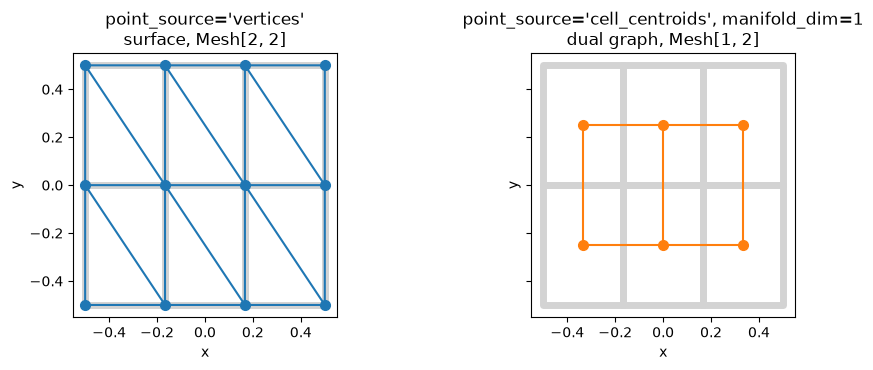

In [4]:
quad_polygons = plane.points[:, :2][plane.regular_faces]  # (n_quads, 4, 2)

fig, (ax_surface, ax_dual) = plt.subplots(
    1, 2, figsize=(10, 3.8), sharex=True, sharey=True
)
for ax in (ax_surface, ax_dual):
    ax.add_collection(
        PolyCollection(
            quad_polygons, facecolors="none", edgecolors="lightgray", linewidths=5
        )
    )

sp = surface.points.numpy()
ax_surface.triplot(sp[:, 0], sp[:, 1], surface.cells.numpy(), color="C0")
ax_surface.plot(sp[:, 0], sp[:, 1], "o", color="C0", markersize=7)
ax_surface.set_title("point_source='vertices'\nsurface, Mesh[2, 2]")

dp = dual.points.numpy()
for a, b in dual.cells.numpy():
    ax_dual.plot(dp[[a, b], 0], dp[[a, b], 1], color="C1")
ax_dual.plot(dp[:, 0], dp[:, 1], "o", color="C1", markersize=7)
ax_dual.set_title(
    "point_source='cell_centroids', manifold_dim=1\ndual graph, Mesh[1, 2]"
)

for ax in (ax_surface, ax_dual):
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
fig.tight_layout()
plt.show()

## 3. Read and Write Files

PhysicsNeMo-Mesh reads and writes other file formats through PyVista.
`to_pyvista` is the inverse of `from_pyvista`. It returns a PyVista mesh with
the fields copied into PyVista arrays. PyVista then writes any format that it
supports, and `pv.read` reads it back.

The cell below builds a surface with data at all three levels, and a nested key:

In [5]:
sphere = sphere_icosahedral.load(subdivisions=2)
sphere.point_data["temperature"] = 300.0 + 20.0 * sphere.points[:, 2]
sphere.point_data["flow", "velocity"] = torch.randn(sphere.n_points, 3)
sphere.cell_data["pressure"] = torch.rand(sphere.n_cells)
sphere.global_data["mach"] = torch.tensor(0.3)

pv_sphere = to_pyvista(sphere)
print(
    f"{type(pv_sphere).__name__}: {pv_sphere.n_points} points, {pv_sphere.n_cells} cells"
)
print(f"point arrays: {pv_sphere.point_data.keys()}")
print(f"cell arrays:  {pv_sphere.cell_data.keys()}")

PolyData: 162 points, 320 cells
point arrays: ['temperature', 'flow/velocity']
cell arrays:  ['pressure']


The nested key `("flow", "velocity")` becomes the flat array name `flow/velocity`.
`to_pyvista` records the nesting in a field-data array, and `from_pyvista`
restores it.

File formats differ in what they can store. VTK's XML formats (`.vtp` for
surfaces, `.vtu` for volumes) keep every array. STL keeps only the triangles:

In [6]:
with tempfile.TemporaryDirectory() as tmp:
    for name in ["sphere.vtp", "sphere.stl"]:
        path = Path(tmp) / name
        pv_sphere.save(path)
        print(f"{name}: {from_pyvista(pv.read(path))}\n")

sphere.vtp: Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=162, n_cells=320)
    point_data : {flow: {velocity: (3,)}, temperature: ()}
    cell_data  : {pressure: ()}
    global_data: {mach: (1,)}

sphere.stl: Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=162, n_cells=320)



The VTP file brings back every field and the nested key. One detail changes. VTK
stores global data as arrays, so the scalar `mach` returns with shape `(1,)`
instead of `()`. To keep a mesh exactly, use the native format of Section 6.

To import your own data, replace the path with your file, for example
`from_pyvista(pv.read("wing.vtu"))`.

## 4. Import a Raw Polygon Mesh

A file reader or a solver can give you raw arrays instead of a PyVista object:
the vertex coordinates and, for each polygon, its ring of vertex indices. The
rings have different lengths, so they do not fit in one dense tensor. Describe
them as an `Adjacency`, the library's compressed sparse row (CSR) container for
ragged lists:

- `indices` is the concatenation of all rings.
- `offsets` holds the start of each ring in `indices`, plus the total length at
  the end. A triangle followed by a quad has `offsets=[0, 3, 7]`.

`triangulate` splits the polygons into triangles. It returns the triangles and,
for each triangle, the index of its source polygon.

In [7]:
points = torch.tensor(
    [
        [0.0, 0.0],  # triangle: vertices 0, 1, 2
        [1.0, 0.0],
        [0.0, 1.0],
        [2.0, 0.0],  # quad: vertices 3, 4, 5, 6
        [3.0, 0.0],
        [3.0, 1.0],
        [2.0, 1.0],
    ]
)
polygons = Adjacency(
    offsets=torch.tensor([0, 3, 7]),
    indices=torch.tensor([0, 1, 2, 3, 4, 5, 6]),
)

cells, parent_index = triangulate(points, polygons)
print(f"triangles:\n{cells}")
print(f"source polygon of each triangle: {parent_index.tolist()}")

triangles:
tensor([[0, 1, 2],
        [3, 4, 5],
        [3, 5, 6]])
source polygon of each triangle: [0, 1, 1]


The source index carries per-polygon data onto the triangles:
`per_triangle = per_polygon[parent_index]`. `Mesh.from_polygons` does both steps
and returns a `Mesh`:

In [8]:
pressure = torch.tensor([10.0, 20.0])  # one value per polygon: triangle, quad
soup = Mesh.from_polygons(points, polygons, cell_data={"pressure": pressure})
print(soup)
print(f"pressure on each triangle: {soup.cell_data['pressure'].tolist()}")

Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=7, n_cells=3)
    cell_data: {pressure: ()}
pressure on each triangle: [10.0, 20.0, 20.0]


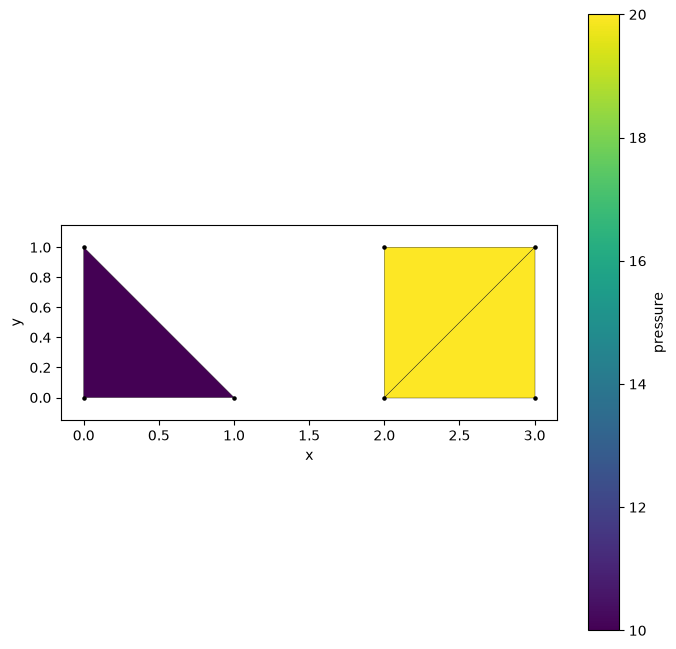

In [9]:
_ = soup.draw(cell_scalars="pressure", cmap="viridis")

## 5. Non-Convex Polygons Need Ear Clipping

The simplest way to split a polygon is a fan from its first vertex: triangles
`(v0, v1, v2)`, `(v0, v2, v3)`, and so on. A fan is correct for a convex polygon,
and `triangulate` uses it as its fast, vectorized path.

For a non-convex polygon, a fan can produce triangles that overlap and extend
outside the polygon. Their areas then do not add up to the polygon's area, which
corrupts every area-weighted quantity, such as a surface integral of pressure.
By default, `triangulate` detects non-convex polygons and splits them by ear
clipping instead, which keeps every triangle inside the polygon.

The "dart" quadrilateral below has a reflex vertex, `v3`, whose interior angle is
over 180 degrees. Its true area is 6.

In [10]:
dart_points = torch.tensor([[0.0, 0.0], [4.0, 2.0], [0.0, 4.0], [1.0, 2.0]])
dart = Adjacency(offsets=torch.tensor([0, 4]), indices=torch.tensor([0, 1, 2, 3]))


def total_area(cells: torch.Tensor) -> float:
    return float(Mesh(points=dart_points, cells=cells).cell_areas.sum())


fan_cells, _ = triangulate(dart_points, dart, assume_convex=True)  # bare fan
ear_cells, _ = triangulate(dart_points, dart)  # default: checks convexity

print(f"fan:          total area = {total_area(fan_cells):.1f}")
print(f"ear clipping: total area = {total_area(ear_cells):.1f}")

fan:          total area = 10.0
ear clipping: total area = 6.0


The figure fills each triangle in translucent red over the dart's outline (blue).
The fan's second triangle lies outside the dart and overlaps the first, so the
overlap shows darker. The ear-clipped triangles tile the dart exactly.

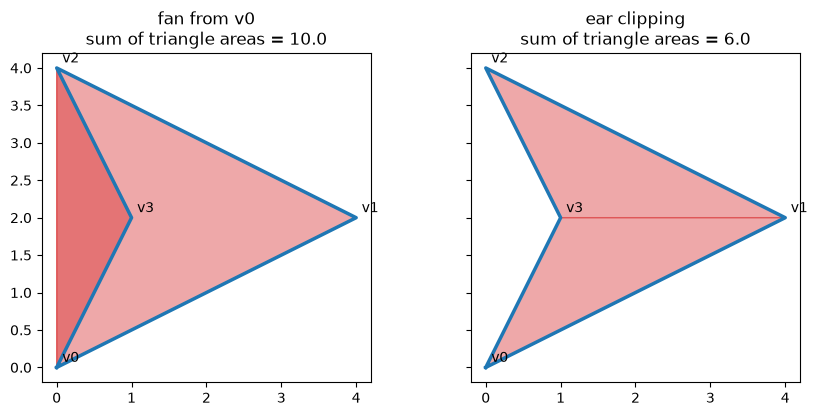

In [11]:
dp = dart_points.numpy()
outline = [0, 1, 2, 3, 0]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, cells, title in [
    (axes[0], fan_cells, "fan from v0"),
    (axes[1], ear_cells, "ear clipping"),
]:
    for triangle in cells.numpy():
        ax.fill(dp[triangle, 0], dp[triangle, 1], color="C3", alpha=0.4)
    ax.plot(dp[outline, 0], dp[outline, 1], color="C0", linewidth=2.5)
    for vertex, (x, y) in enumerate(dp):
        ax.annotate(f"v{vertex}", (x, y), textcoords="offset points", xytext=(4, 4))
    ax.set_title(f"{title}\nsum of triangle areas = {total_area(cells):.1f}")
    ax.set_aspect("equal")
fig.tight_layout()
plt.show()

Pass `assume_convex=True` only when you know that every polygon is convex, as is
common for computational fluid dynamics (CFD) surface cells. It skips the
convexity test, and it is the only path of `triangulate` that `torch.compile` can
trace with no graph break.

## 6. Save and Load in the Native Format

`Mesh.save(path)` and `Mesh.load(path)` store a mesh exactly, with all of its data,
dtypes, and nested keys. Use them instead of `torch.save`, which pickles the
object. Loading a pickle can run arbitrary code, and the native format does not
use pickle.

The native format is a directory of memory-mapped tensor files, one file for each
tensor. By convention, the directory name ends in `.pmsh` for a `Mesh` and
`.pdmsh` for a `DomainMesh`. The mesh readers in `physicsnemo.datapipes` look for
these extensions.

The cell below adds a field at each level to the polygon mesh of Section 4, saves
it, prints the directory tree, and loads it back. A small helper prints the tree.

In [12]:
def print_tree(root: Path, prefix: str = "", *, show_cache: bool = True) -> None:
    """Print a ``tree``-style listing of ``root``, with each file's size in bytes.

    Pass ``show_cache=False`` to hide the internal ``_cache`` folders.
    """
    entries = sorted(
        (p for p in root.iterdir() if show_cache or p.name != "_cache"),
        key=lambda p: (p.is_file(), p.name),
    )
    for i, entry in enumerate(entries):
        is_last = i == len(entries) - 1
        annotation = f"  [{entry.stat().st_size:,} B]" if entry.is_file() else "/"
        print(f"{prefix}{'`-- ' if is_last else '|-- '}{entry.name}{annotation}")
        if entry.is_dir():
            print_tree(
                entry, prefix + ("    " if is_last else "|   "), show_cache=show_cache
            )

In [13]:
soup.point_data["temperature"] = torch.linspace(300.0, 320.0, soup.n_points)
soup.global_data["mach"] = torch.tensor(0.3)
soup.global_data["freestream", "velocity"] = torch.tensor([30.0, 0.0])

with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "soup.pmsh"
    soup.save(path)
    print(f"{path.name}/")
    print_tree(path)

    reloaded = Mesh.load(path)
    print(f"\nreloaded: {reloaded}")
    same = all(
        torch.equal(a, b)
        for a, b in [
            (soup.points, reloaded.points),
            (soup.cells, reloaded.cells),
            (soup.point_data["temperature"], reloaded.point_data["temperature"]),
            (soup.cell_data["pressure"], reloaded.cell_data["pressure"]),
            (soup.global_data["mach"], reloaded.global_data["mach"]),
        ]
    )
    print(f"all fields round-trip exactly: {same}")

soup.pmsh/
|-- _tensordict/
|   |-- _cache/
|   |   |-- cell/
|   |   |   `-- meta.json  [79 B]
|   |   |-- point/
|   |   |   `-- meta.json  [79 B]
|   |   |-- topology/
|   |   |   `-- meta.json  [78 B]
|   |   `-- meta.json  [179 B]
|   |-- cell_data/
|   |   |-- meta.json  [170 B]
|   |   `-- pressure.memmap  [12 B]
|   |-- global_data/
|   |   |-- freestream/
|   |   |   |-- meta.json  [169 B]
|   |   |   `-- velocity.memmap  [8 B]
|   |   |-- mach.memmap  [4 B]
|   |   `-- meta.json  [202 B]
|   |-- point_data/
|   |   |-- meta.json  [173 B]
|   |   `-- temperature.memmap  [28 B]
|   |-- cells.memmap  [72 B]
|   |-- meta.json  [407 B]
|   `-- points.memmap  [56 B]
`-- meta.json  [49 B]

reloaded: Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=7, n_cells=3, device=cpu)
    point_data : {temperature: ()}
    cell_data  : {pressure: ()}
    global_data: {freestream: {velocity: (2,)}, mach: ()}
all fields round-trip exactly: True


The tree mirrors the `Mesh` object, under a `_tensordict/` folder:

- Each tensor is a raw `.memmap` file of `numel * itemsize` bytes. For example,
  `points.memmap` holds 7 x 2 `float32` values, so it is 56 bytes.
- Each folder has a `meta.json` file with the shapes, dtypes, and class of its
  contents. `Mesh.load` uses it to rebuild a `Mesh`, not a plain dictionary.
- The `point_data/`, `cell_data/`, and `global_data/` folders hold the fields. A
  nested key becomes a subfolder, such as `global_data/freestream/`.
- `_cache/` holds cached geometry, such as cell areas, so that a loaded mesh does
  not compute it again. It is empty here, because no code read a geometric
  property of this mesh before the save.

Because the files are memory-mapped, the loaded tensors read from disk only when
you use them. `Mesh.load(path, device="cuda")` moves the mesh to a GPU as it loads.

### DomainMesh: The Same Format, Nested

A `DomainMesh` groups the meshes of one simulation case: an interior mesh, named
boundary meshes, and case-level `global_data` such as the Reynolds number.
Tutorial 8 covers it. A `DomainMesh` saves with the same format, one level
deeper. The interior and each boundary get their own mesh tree.

In [14]:
interior = Mesh(
    points=torch.tensor(
        [[0.0, 0.0, 0.0], [1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
    ),
    cells=torch.tensor([[0, 1, 2, 3]]),
    point_data={"wall_distance": torch.tensor([0.0, 1.0, 1.0, 1.0])},
)
wall = Mesh(
    points=torch.tensor([[0.0, 0.0, 0.0], [1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]),
    cells=torch.tensor([[0, 1, 2]]),
    cell_data={"pressure": torch.tensor([101.3])},
)
inlet = Mesh(
    points=torch.tensor([[0.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]),
    cells=torch.tensor([[0, 1, 2]]),
)
domain = DomainMesh(
    interior=interior,
    boundaries={"no_slip": wall, "inlet": inlet},
    global_data={"Re": torch.tensor(1.0e6), "AoA": torch.tensor(5.0)},
)

with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "domain.pdmsh"
    domain.save(path)
    print(f"{path.name}/")
    print_tree(path, show_cache=False)  # hide the _cache folders

    reloaded = DomainMesh.load(path)
    print(f"\nreloaded boundaries: {reloaded.boundary_names}")
    print(f"Re: {reloaded.global_data['Re'].item():.0e}")

domain.pdmsh/
|-- _tensordict/
|   |-- boundaries/
|   |   |-- inlet/
|   |   |   |-- _tensordict/
|   |   |   |   |-- cell_data/
|   |   |   |   |   `-- meta.json  [79 B]
|   |   |   |   |-- global_data/
|   |   |   |   |   `-- meta.json  [78 B]
|   |   |   |   |-- point_data/
|   |   |   |   |   `-- meta.json  [79 B]
|   |   |   |   |-- cells.memmap  [24 B]
|   |   |   |   |-- meta.json  [407 B]
|   |   |   |   `-- points.memmap  [36 B]
|   |   |   `-- meta.json  [49 B]
|   |   |-- no_slip/
|   |   |   |-- _tensordict/
|   |   |   |   |-- cell_data/
|   |   |   |   |   |-- meta.json  [170 B]
|   |   |   |   |   `-- pressure.memmap  [4 B]
|   |   |   |   |-- global_data/
|   |   |   |   |   `-- meta.json  [78 B]
|   |   |   |   |-- point_data/
|   |   |   |   |   `-- meta.json  [79 B]
|   |   |   |   |-- cells.memmap  [24 B]
|   |   |   |   |-- meta.json  [407 B]
|   |   |   |   `-- points.memmap  [36 B]
|   |   |   `-- meta.json  [49 B]
|   |   `-- meta.json  [134 B]
|   |-- global_d

### Zarr: Chunked and Compressed Stores for Training Data

The native format suits one mesh that you load whole: a checkpoint, a test case,
or a cache between steps of a pipeline. For a training set of large meshes, a
training step often needs only part of each mesh, such as a random subsample of
its cells. `to_zarr` writes a mesh or a domain to a [Zarr](https://zarr.dev)
store, which splits each array into compressed chunks along its first dimension.
The mesh readers in `physicsnemo.datapipes` read `.zarr` stores, and they fetch
only the chunks that a subsample needs.

`to_zarr` takes the chunk length (`chunk_rows`, 200,000 rows by default) and the
zstd compression level (`zstd_level`, 3 by default, 0 for no compression).
`from_zarr` reads the whole store back into memory. The round trip keeps nested
keys and scalar global data:

In [15]:
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "sphere.zarr"
    with warnings.catch_warnings():
        # See the note below the cell.
        warnings.filterwarnings("ignore", message="Consolidated metadata")
        to_zarr(sphere, path, chunk_rows=64)
    reloaded = from_zarr(path)

print(reloaded)
same = torch.equal(sphere.points, reloaded.points) and torch.equal(
    sphere.point_data["flow", "velocity"], reloaded.point_data["flow", "velocity"]
)
print(f"points and nested velocity round-trip exactly: {same}")
print(f"mach shape: {tuple(reloaded.global_data['mach'].shape)}")

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=162, n_cells=320)
    point_data : {flow: {velocity: (3,)}, temperature: ()}
    cell_data  : {pressure: ()}
    global_data: {mach: ()}
points and nested velocity round-trip exactly: True
mach shape: ()


The mesh is the sphere of Section 3. Unlike its VTP file, the Zarr store keeps
`mach` as a scalar, with shape `()`.

`to_zarr` consolidates the metadata of the store into one file, so that opening
the store costs one metadata read instead of one for each group. This helps on
networked file systems. The `zarr` package warns that consolidated metadata is
not yet part of the Zarr version 3 specification. The cell above hides that
warning. `from_zarr` and the datapipe readers read consolidated stores.

## Summary

This tutorial covered the following points:

- A `Mesh` holds only simplices, so importing a mesh with quads or polygons means
  splitting them. `from_pyvista` does this automatically.
- `from_pyvista(..., point_source="cell_centroids", manifold_dim=1)` gives the dual
  graph of a mesh, with one node for each cell.
- `to_pyvista` and `pv.read` connect PhysicsNeMo-Mesh to every format that PyVista
  supports. VTK XML files keep the data, and STL files do not.
- For raw arrays, describe the polygons with an `Adjacency` and call `triangulate`
  or `Mesh.from_polygons`. The source index of each triangle carries polygon data.
- `triangulate` ear-clips non-convex polygons by default, so areas stay correct.
- `save` and `load` store a `Mesh` or a `DomainMesh` exactly, as a directory of
  memory-mapped tensors (`.pmsh` or `.pdmsh`), without pickle.
- `to_zarr` and `from_zarr` store meshes in chunked, compressed Zarr stores, which
  training pipelines can read in parts.

## Next Steps

Continue with the following resources:

- [Tutorial 3: Primitives and Mesh Generation](tutorial_3_primitives_generation.ipynb)
  builds meshes from scratch: the example meshes in `physicsnemo.mesh.primitives`,
  filling a boundary with triangles, and meshing implicit shapes.
- API Reference: [I/O](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/io.html)
  and [tessellation](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/tessellation.html).
- User Guide: [Using PhysicsNeMo-Mesh](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/using_mesh.html).